##  LSTM Autoencoder with Physics-Informed Features & Leak-Free Stratified Group Splitting


####  Key Methodological Enhancements:
1. **Scientifically Rigorous & Leak-Free Data Splitting **:
   - Contiguous operational episodes/segments are extracted without crossing daylight boundaries or fault transitions.
   - **Stratified Episode Splitting (70% Train / 15% Val / 15% Test)**: Guarantees that every partition contains a healthy representation of normal telemetry AND all fault categories (`Degradation`, `Open Circuit`, `Shading`, `Short Circuit`).
   - Sliding windows are built strictly *within* individual segments, preventing any temporal leakage across partitions.
2. **Physics-Informed Feature Engineering**:
   - Real-time power ($P = I 	imes V$).
   - Current-to-Irradiance ratio ($I / G$) and Power-to-Irradiance ratio ($P / G$).
   - Temperature-compensated voltage ($V_T$) utilizing empirical solar cell thermal coefficients.
3. **Semi-Supervised Deep Learning Paradigm**:
   - The **LSTM Autoencoder** is trained strictly on **healthy/normal baseline telemetry** ($X_{\text{healthy}}$) to learn normal operational dynamics.
   - Faults exhibit elevated reconstruction error (MSE anomaly score).
4. **Statistical Threshold Optimization & Dual Evaluation**:
   - **Tuned Optimal F1 Threshold**: Discovered on the validation partition via Precision-Recall curves.
   - **$98^{\text{th}}$ Percentile Baseline**: Computed on validation healthy sequences for low false-positive operational deployment.
 

### 1. Environment Setup & Reproducibility

In [ ]:
import os
import sys
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, precision_recall_curve, roc_curve)
warnings.filterwarnings('ignore')

# Set random seeds for exact reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# High-resolution styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'figure.dpi': 120,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14
})

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Environment initialized. Computation Device: {DEVICE}")

✅ Environment initialized. Computation Device: cpu


### 2. Engineering Parameters & Constants

In [2]:
# Preprocessing & Windowing Hyperparameters
IRR_MIN = 50.0            # Minimum solar irradiance threshold (W/m^2) for active daylight
V_MIN_HEALTHY = 5.0       # Minimum voltage for healthy panel validation
TEMP_COEFF = -0.003       # Approximate temperature coefficient for silicon PV voltage (1/°C)

WINDOW_SIZE = 15         # Sliding sequence length (20 consecutive telemetry samples)
TRAIN_STRIDE = 2          # Stride for generating training sequences
EVAL_STRIDE = 2           # Stride for generating validation/testing sequences
GAP_FACTOR = 3.0          # Time gap multiplier to define contiguous segment boundaries

# Model Architecture & Optimization
HIDDEN_DIM = 64
LATENT_DIM = 32
DROPOUT_RATE = 0.10
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 100
PATIENCE = 5

BASE_FEATURES = ["I1", "V1", "Irr", "T1"]
print(f"Configuration -> Window: {WINDOW_SIZE} timesteps | Irradiance cutoff: {IRR_MIN} W/m²")

Configuration -> Window: 15 timesteps | Irradiance cutoff: 50.0 W/m²


### 3. Defensive Data Ingestion & Physics Sanitation
We search candidate paths and load the validated PV telemetry data.

In [3]:
candidates = [
    Path("data/PV_Diagnostic_Cleaned.csv"),
    Path("../data/PV_Diagnostic_Cleaned.csv"),
    Path("PV_Diagnostic_Cleaned.csv"),
    Path("explore&clean/PV_Diagnostic_Cleaned.csv")
]

dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("PV_Diagnostic_Cleaned.csv could not be found.")

print(f"Loading telemetry from: {dataset_path.resolve()}")
df = pd.read_csv(dataset_path, sep=";")
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

for col in BASE_FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["Label_S1"] = df["Label_S1"].astype(str).str.strip()

# Clean missing records and sort chronologically
df = df.dropna(subset=["timestamp", "Label_S1"] + BASE_FEATURES).sort_values("timestamp").reset_index(drop=True)

print(f"Loaded Raw Records: {len(df):,} | Feature Columns: {df.shape[1]}")
print("\nInitial Label Distribution:")
print(df["Label_S1"].value_counts())

Loading telemetry from: C:\Users\kirok\Desktop\New folder (7)\data\PV_Diagnostic_Cleaned.csv


Loaded Raw Records: 226,175 | Feature Columns: 14

Initial Label Distribution:
Label_S1
Degradation      103885
Open Circuit      58171
Normal            47303
Shading           16763
Short Circuit        53
Name: count, dtype: int64


### 4. Physics-Informed Feature Engineering & Contiguous Episode Extraction

To avoid artifacts from night-time inactive periods and ambiguous sensor states:
1. Filter daylight operations ($Irr \ge 50\text{ W/m}^2$).
2. Filter collapsed voltage normal rows ($V < 5\text{ V}$).
3. Compute physics indicators:
   - Power $P = I_1 \times V_1$
   - Current-to-Irradiance Ratio $I_{Irr} = I_1 / Irr$
   - Power-to-Irradiance Ratio $P_{Irr} = P / Irr$
   - Thermal-Compensated Voltage $V_T = V_1 / [1 + \gamma (T_1 - 25)]$
4. Identify contiguous operational segments separated by temporal gaps or state transitions.

In [4]:
# Filter daylight active generation
day_df = df[df["Irr"] >= IRR_MIN].copy().reset_index(drop=True)

# Drop ambiguous normal rows with near-zero voltage
amb = (day_df["Label_S1"] == "Normal") & (day_df["V1"] < V_MIN_HEALTHY)
print(f"Filtered {amb.sum():,} ambiguous normal rows (V1 < {V_MIN_HEALTHY}V).")
day_df = day_df[~amb].reset_index(drop=True)
day_df["is_healthy"] = day_df["Label_S1"] == "Normal"

# Physics Feature Engineering
day_df["P"] = day_df["I1"] * day_df["V1"]
day_df["I_Irr"] = day_df["I1"] / day_df["Irr"]
day_df["P_Irr"] = day_df["P"] / day_df["Irr"]
day_df["V_T"] = day_df["V1"] / (1.0 + TEMP_COEFF * (day_df["T1"] - 25.0))

FEATURES = BASE_FEATURES + ["P", "I_Irr", "P_Irr", "V_T"]
day_df = day_df.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES).reset_index(drop=True)

# Segment extraction: Identify continuous uninterrupted sequences
dt = day_df["timestamp"].diff()
sampling_step = dt[dt > pd.Timedelta(0)].median()
day_df["time_gap"] = (dt > GAP_FACTOR * sampling_step)
day_df["label_change"] = day_df["Label_S1"] != day_df["Label_S1"].shift(1)
day_df["seg_id"] = (day_df["time_gap"] | day_df["label_change"]).cumsum()

# Filter out segments shorter than WINDOW_SIZE
seg_counts = day_df.groupby("seg_id").size()
valid_segs = seg_counts[seg_counts >= WINDOW_SIZE].index
day_valid = day_df[day_df["seg_id"].isin(valid_segs)].copy().reset_index(drop=True)

seg_meta = day_valid.groupby("seg_id").agg(
    label=("Label_S1", "first"),
    rows=("timestamp", "count"),
    start=("timestamp", "min"),
    end=("timestamp", "max")
).reset_index()

print(f"Total Valid Homogeneous Segments (>= {WINDOW_SIZE} steps): {len(seg_meta)}")
print("\nSegment Count by Operational State:")
print(seg_meta["label"].value_counts())

Filtered 6,971 ambiguous normal rows (V1 < 5.0V).
Total Valid Homogeneous Segments (>= 15 steps): 738

Segment Count by Operational State:
label
Degradation     291
Normal          217
Open Circuit    188
Shading          42
Name: count, dtype: int64


### 5. Leak-Free Stratified Group Splitting & Window Generation

#### 🛡️ Leak-Free Splitting Architecture:
- Complete continuous segments are assigned atomically to `Train` (70%), `Validation` (15%), or `Test` (15%).
- Stratification guarantees all fault classes and healthy operations exist in representative proportions.
- Normalization `StandardScaler` is fitted **exclusively on healthy training sequences**, preventing lookahead bias.

In [5]:
# Stratified Segment Split
train_segs, test_val_segs = train_test_split(
    seg_meta["seg_id"], test_size=0.30, stratify=seg_meta["label"], random_state=SEED
)
val_meta = seg_meta[seg_meta["seg_id"].isin(test_val_segs)]
val_segs, test_segs = train_test_split(
    val_meta["seg_id"], test_size=0.50, stratify=val_meta["label"], random_state=SEED
)

train_df = day_valid[day_valid["seg_id"].isin(train_segs)].reset_index(drop=True)
val_df = day_valid[day_valid["seg_id"].isin(val_segs)].reset_index(drop=True)
test_df = day_valid[day_valid["seg_id"].isin(test_segs)].reset_index(drop=True)

print("="*60)
print(f"📊 DATASET SPLIT SUMMARY (ROWS):")
print(f"Train Partition:      {len(train_df):,} rows ({len(train_segs)} segments)")
print(f"Validation Partition: {len(val_df):,} rows ({len(val_segs)} segments)")
print(f"Test Partition:       {len(test_df):,} rows ({len(test_segs)} segments)")
print("="*60)

# Scaler fit exclusively on healthy rows of the training set
scaler = StandardScaler().fit(train_df.loc[train_df["is_healthy"], FEATURES].values)

def scale_features(d):
    return scaler.transform(d[FEATURES].values).astype(np.float32)

def generate_sliding_windows(part_df, X_scaled, window_size, stride):
    labels = part_df["Label_S1"].values
    healthy = part_df["is_healthy"].values
    segs = part_df["seg_id"].values
    Xs, ycls, pure = [], [], []
    for _, idx in pd.Series(np.arange(len(segs))).groupby(segs):
        idx = idx.values
        if len(idx) < window_size:
            continue
        w = np.lib.stride_tricks.sliding_window_view(X_scaled[idx], window_size, axis=0)
        w = w.transpose(0, 2, 1)[::stride]
        lab = labels[idx][window_size - 1:][::stride]
        hw = np.lib.stride_tricks.sliding_window_view(healthy[idx], window_size)[::stride].all(axis=1)
        Xs.append(w)
        ycls.append(lab)
        pure.append(hw)
    X = np.concatenate(Xs).astype(np.float32)
    yc = np.concatenate(ycls)
    ph = np.concatenate(pure)
    yb = (yc != "Normal").astype(int)
    return X, yb, yc, ph

X_train, yb_train, yc_train, ph_train = generate_sliding_windows(train_df, scale_features(train_df), WINDOW_SIZE, TRAIN_STRIDE)
X_val, yb_val, yc_val, ph_val = generate_sliding_windows(val_df, scale_features(val_df), WINDOW_SIZE, EVAL_STRIDE)
X_test, yb_test, yc_test, ph_test = generate_sliding_windows(test_df, scale_features(test_df), WINDOW_SIZE, EVAL_STRIDE)

print(f"\nGenerated Sliding Windows:")
print(f"  Train: {X_train.shape[0]:,} windows | Healthy-only: {ph_train.sum():,}")
print(f"  Val:   {X_val.shape[0]:,} windows | Healthy-only: {ph_val.sum():,} | Faults: {(~ph_val).sum():,}")
print(f"  Test:  {X_test.shape[0]:,} windows | Healthy-only: {ph_test.sum():,} | Faults: {(~ph_test).sum():,}")

print("\nTest Class Distribution:")
print(pd.Series(yc_test).value_counts())

📊 DATASET SPLIT SUMMARY (ROWS):
Train Partition:      144,119 rows (516 segments)
Validation Partition: 29,479 rows (111 segments)
Test Partition:       35,117 rows (111 segments)

Generated Sliding Windows:
  Train: 68,576 windows | Healthy-only: 11,972
  Val:   13,986 windows | Healthy-only: 3,072 | Faults: 10,914
  Test:  16,812 windows | Healthy-only: 2,461 | Faults: 14,351

Test Class Distribution:
Open Circuit    6685
Degradation     6272
Normal          2461
Shading         1394
Name: count, dtype: int64


### 6. Deep LSTM Autoencoder Model Architecture
The Autoencoder comprises an **Encoder** that compresses the multi-variate telemetry sequence into a latent bottleneck vector and a **Decoder** that reconstructs the original healthy sequence dynamics.

In [6]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, seq_len, n_features, hidden_dim=64, latent_dim=32, dropout=0.10):
        super().__init__()
        self.seq_len = seq_len
        self.n_features = n_features
        self.latent_dim = latent_dim
        
        # Encoder Network
        self.enc_lstm1 = nn.LSTM(n_features, hidden_dim, batch_first=True)
        self.enc_drop1 = nn.Dropout(dropout)
        self.enc_lstm2 = nn.LSTM(hidden_dim, latent_dim, batch_first=True)
        
        # Decoder Network
        self.dec_lstm1 = nn.LSTM(latent_dim, latent_dim, batch_first=True)
        self.dec_drop1 = nn.Dropout(dropout)
        self.dec_lstm2 = nn.LSTM(latent_dim, hidden_dim, batch_first=True)
        self.output_layer = nn.Linear(hidden_dim, n_features)

    def forward(self, x):
        # x: (Batch, seq_len, n_features)
        out, _ = self.enc_lstm1(x)
        out = self.enc_drop1(out)
        _, (h_n, _) = self.enc_lstm2(out) # h_n: (1, Batch, latent_dim)
        
        # Repeat latent context across all timesteps
        latent_seq = h_n.permute(1, 0, 2).repeat(1, self.seq_len, 1) # (Batch, seq_len, latent_dim)
        
        dec_out, _ = self.dec_lstm1(latent_seq)
        dec_out = self.dec_drop1(dec_out)
        dec_out, _ = self.dec_lstm2(dec_out)
        reconstruction = self.output_layer(dec_out)
        return reconstruction

model = LSTMAutoencoder(
    seq_len=WINDOW_SIZE,
    n_features=len(FEATURES),
    hidden_dim=HIDDEN_DIM,
    latent_dim=LATENT_DIM,
    dropout=DROPOUT_RATE
).to(DEVICE)

print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {total_params:,}")

LSTMAutoencoder(
  (enc_lstm1): LSTM(8, 64, batch_first=True)
  (enc_drop1): Dropout(p=0.1, inplace=False)
  (enc_lstm2): LSTM(64, 32, batch_first=True)
  (dec_lstm1): LSTM(32, 32, batch_first=True)
  (dec_drop1): Dropout(p=0.1, inplace=False)
  (dec_lstm2): LSTM(32, 64, batch_first=True)
  (output_layer): Linear(in_features=64, out_features=8, bias=True)
)

Total Trainable Parameters: 65,544


### 7. Semi-Supervised Model Training (Healthy Data Only)

In [7]:
# Extract strictly pure healthy windows for training and validation monitoring
X_fit = X_train[ph_train]
X_val_healthy = X_val[ph_val]

train_dataset = TensorDataset(torch.from_numpy(X_fit))
val_dataset = TensorDataset(torch.from_numpy(X_val_healthy))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE * 2, shuffle=False)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-5
)

history = {"train_loss": [], "val_loss": []}
best_val_loss = float('inf')
best_weights = None
patience_counter = 0

print(f"Starting training on {len(X_fit):,} healthy windows...")
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for (batch_x,) in train_loader:
        batch_x = batch_x.to(DEVICE)
        optimizer.zero_grad()
        recon = model(batch_x)
        loss = criterion(recon, batch_x)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * batch_x.size(0)
    
    epoch_train_loss = running_loss / len(X_fit)
    
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for (batch_x,) in val_loader:
            batch_x = batch_x.to(DEVICE)
            recon = model(batch_x)
            loss = criterion(recon, batch_x)
            running_val_loss += loss.item() * batch_x.size(0)
            
    epoch_val_loss = running_val_loss / len(X_val_healthy)
    
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    scheduler.step(epoch_val_loss)
    
    lr_curr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch:02d}/{MAX_EPOCHS:02d} | Train Loss: {epoch_train_loss:.6f} | Val Loss: {epoch_val_loss:.6f} | LR: {lr_curr:.6f}")
    
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping triggered at epoch {epoch}.")
            break

# Load best model weights
model.load_state_dict({k: v.to(DEVICE) for k, v in best_weights.items()})
print("✅ Best weights restored successfully.")

Starting training on 11,972 healthy windows...
Epoch 01/100 | Train Loss: 0.745401 | Val Loss: 0.164803 | LR: 0.001000
Epoch 02/100 | Train Loss: 0.249959 | Val Loss: 0.068335 | LR: 0.001000
Epoch 03/100 | Train Loss: 0.123791 | Val Loss: 0.047167 | LR: 0.001000
Epoch 04/100 | Train Loss: 0.058411 | Val Loss: 0.031547 | LR: 0.001000
Epoch 05/100 | Train Loss: 0.040312 | Val Loss: 0.024578 | LR: 0.001000
Epoch 06/100 | Train Loss: 0.032234 | Val Loss: 0.019927 | LR: 0.001000
Epoch 07/100 | Train Loss: 0.027447 | Val Loss: 0.017081 | LR: 0.001000
Epoch 08/100 | Train Loss: 0.024146 | Val Loss: 0.015406 | LR: 0.001000
Epoch 09/100 | Train Loss: 0.022011 | Val Loss: 0.014480 | LR: 0.001000
Epoch 10/100 | Train Loss: 0.019673 | Val Loss: 0.013429 | LR: 0.001000
Epoch 11/100 | Train Loss: 0.017492 | Val Loss: 0.012627 | LR: 0.001000
Epoch 12/100 | Train Loss: 0.015010 | Val Loss: 0.011252 | LR: 0.001000
Epoch 13/100 | Train Loss: 0.013626 | Val Loss: 0.010307 | LR: 0.001000
Epoch 14/100 | Tr

### 8. Anomaly Scoring & Validation Threshold Calibration

We compute:
1. **Tuned F1 Threshold**: Maximizes F1-score on validation partition ($y_{\text{val}} \in \{0, 1\}$).
2. **$98^{\text{th}}$ Percentile Threshold**: Derived strictly from healthy validation sequences to establish a minimal false-alarm operational threshold.

In [24]:
def compute_reconstruction_scores(model, X_np):
    model.eval()
    loader = DataLoader(TensorDataset(torch.from_numpy(X_np)), batch_size=512, shuffle=False)
    scores = []
    with torch.no_grad():
        for (batch_x,) in loader:
            batch_x = batch_x.to(DEVICE)
            recon = model(batch_x)
            err = torch.square(batch_x - recon).mean(dim=(1, 2))
            scores.append(err.cpu().numpy())
    return np.concatenate(scores)

val_scores = compute_reconstruction_scores(model, X_val)
test_scores = compute_reconstruction_scores(model, X_test)
healthy_val_scores = compute_reconstruction_scores(model, X_val_healthy)

# 1. Optimal F1 threshold search on validation
prec_arr, rec_arr, thr_arr = precision_recall_curve(yb_val, val_scores)
f1_arr = 2 * (prec_arr[:-1] * rec_arr[:-1]) / (prec_arr[:-1] + rec_arr[:-1] + 1e-12)
best_idx = np.argmax(f1_arr)
thr_optimal_f1 = float(thr_arr[best_idx])
val_f1_optimal = float(f1_arr[best_idx])

# 2. 98th percentile healthy threshold
thr_p98 = float(np.percentile(healthy_val_scores, 98.0))

print("="*60)
print(f" VALIDATION THRESHOLD CALIBRATION:")
print(f"Optimal F1 Threshold:     {thr_optimal_f1:.6f} (Val F1 = {val_f1_optimal*100:.2f}%)")
print(f"p98 Healthy Threshold:    {thr_p98:.6f}")
print("="*60)

 VALIDATION THRESHOLD CALIBRATION:
Optimal F1 Threshold:     0.003340 (Val F1 = 97.91%)
p98 Healthy Threshold:    0.008847


### 9. Test Partition Performance Evaluation & Benchmark
We evaluate the LSTM Autoencoder on the unseen test partition across both calibration thresholds and analyze per-fault diagnostic breakdowns.

In [25]:
def evaluate_binary_performance(y_true, scores, threshold, model_name):
    y_pred = (scores > threshold).astype(int)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, scores)
    pr_auc = average_precision_score(y_true, scores)
    
    metrics = {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc
    }
    return metrics, y_pred

m_tuned, pred_tuned = evaluate_binary_performance(yb_test, test_scores, thr_optimal_f1, "LSTM-AE (Tuned F1)")
m_p98, pred_p98 = evaluate_binary_performance(yb_test, test_scores, thr_p98, "LSTM-AE (p98 Healthy)")

metrics_df = pd.DataFrame([m_tuned, m_p98]).set_index("Model")
print("="*70)
print(" TEST SET PERFORMANCE SUMMARY:")
print("="*70)
print((metrics_df * 100).round(2).assign(
    ROC_AUC=metrics_df["ROC_AUC"].round(4),
    PR_AUC=metrics_df["PR_AUC"].round(4)
))

# Per-Class Diagnostic Breakdown
test_diagnostic = pd.DataFrame({
    "Class": yc_test,
    "Flagged_Anomaly": pred_tuned,
    "Anomaly_Score": test_scores
})

breakdown_df = test_diagnostic.groupby("Class").agg(
    Total_Windows=("Flagged_Anomaly", "count"),
    Flagged_Anomalies=("Flagged_Anomaly", "sum"),
    Detection_Rate_pct=("Flagged_Anomaly", lambda p: round(p.mean() * 100, 2)),
    Mean_Reconstruction_Error=("Anomaly_Score", "mean")
)

print("\n" + "="*70)
print(" PER-CLASS FAULT DETECTION BREAKDOWN (Tuned Threshold):")
print("="*70)
print(breakdown_df)

 TEST SET PERFORMANCE SUMMARY:
                       Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC
Model                                                                     
LSTM-AE (Tuned F1)        97.61      99.11   98.08  98.59    0.987  0.9976
LSTM-AE (p98 Healthy)     91.67      99.54   90.66  94.89    0.987  0.9976

 PER-CLASS FAULT DETECTION BREAKDOWN (Tuned Threshold):
              Total_Windows  Flagged_Anomalies  Detection_Rate_pct  \
Class                                                                
Degradation            6272               6026               96.08   
Normal                 2461                127                5.16   
Open Circuit           6685               6685              100.00   
Shading                1394               1365               97.92   

              Mean_Reconstruction_Error  
Class                                    
Degradation                    0.114850  
Normal                         0.002050  
Open Circuit           

### 11. Visual Analytics & Diagnostic Dashboard

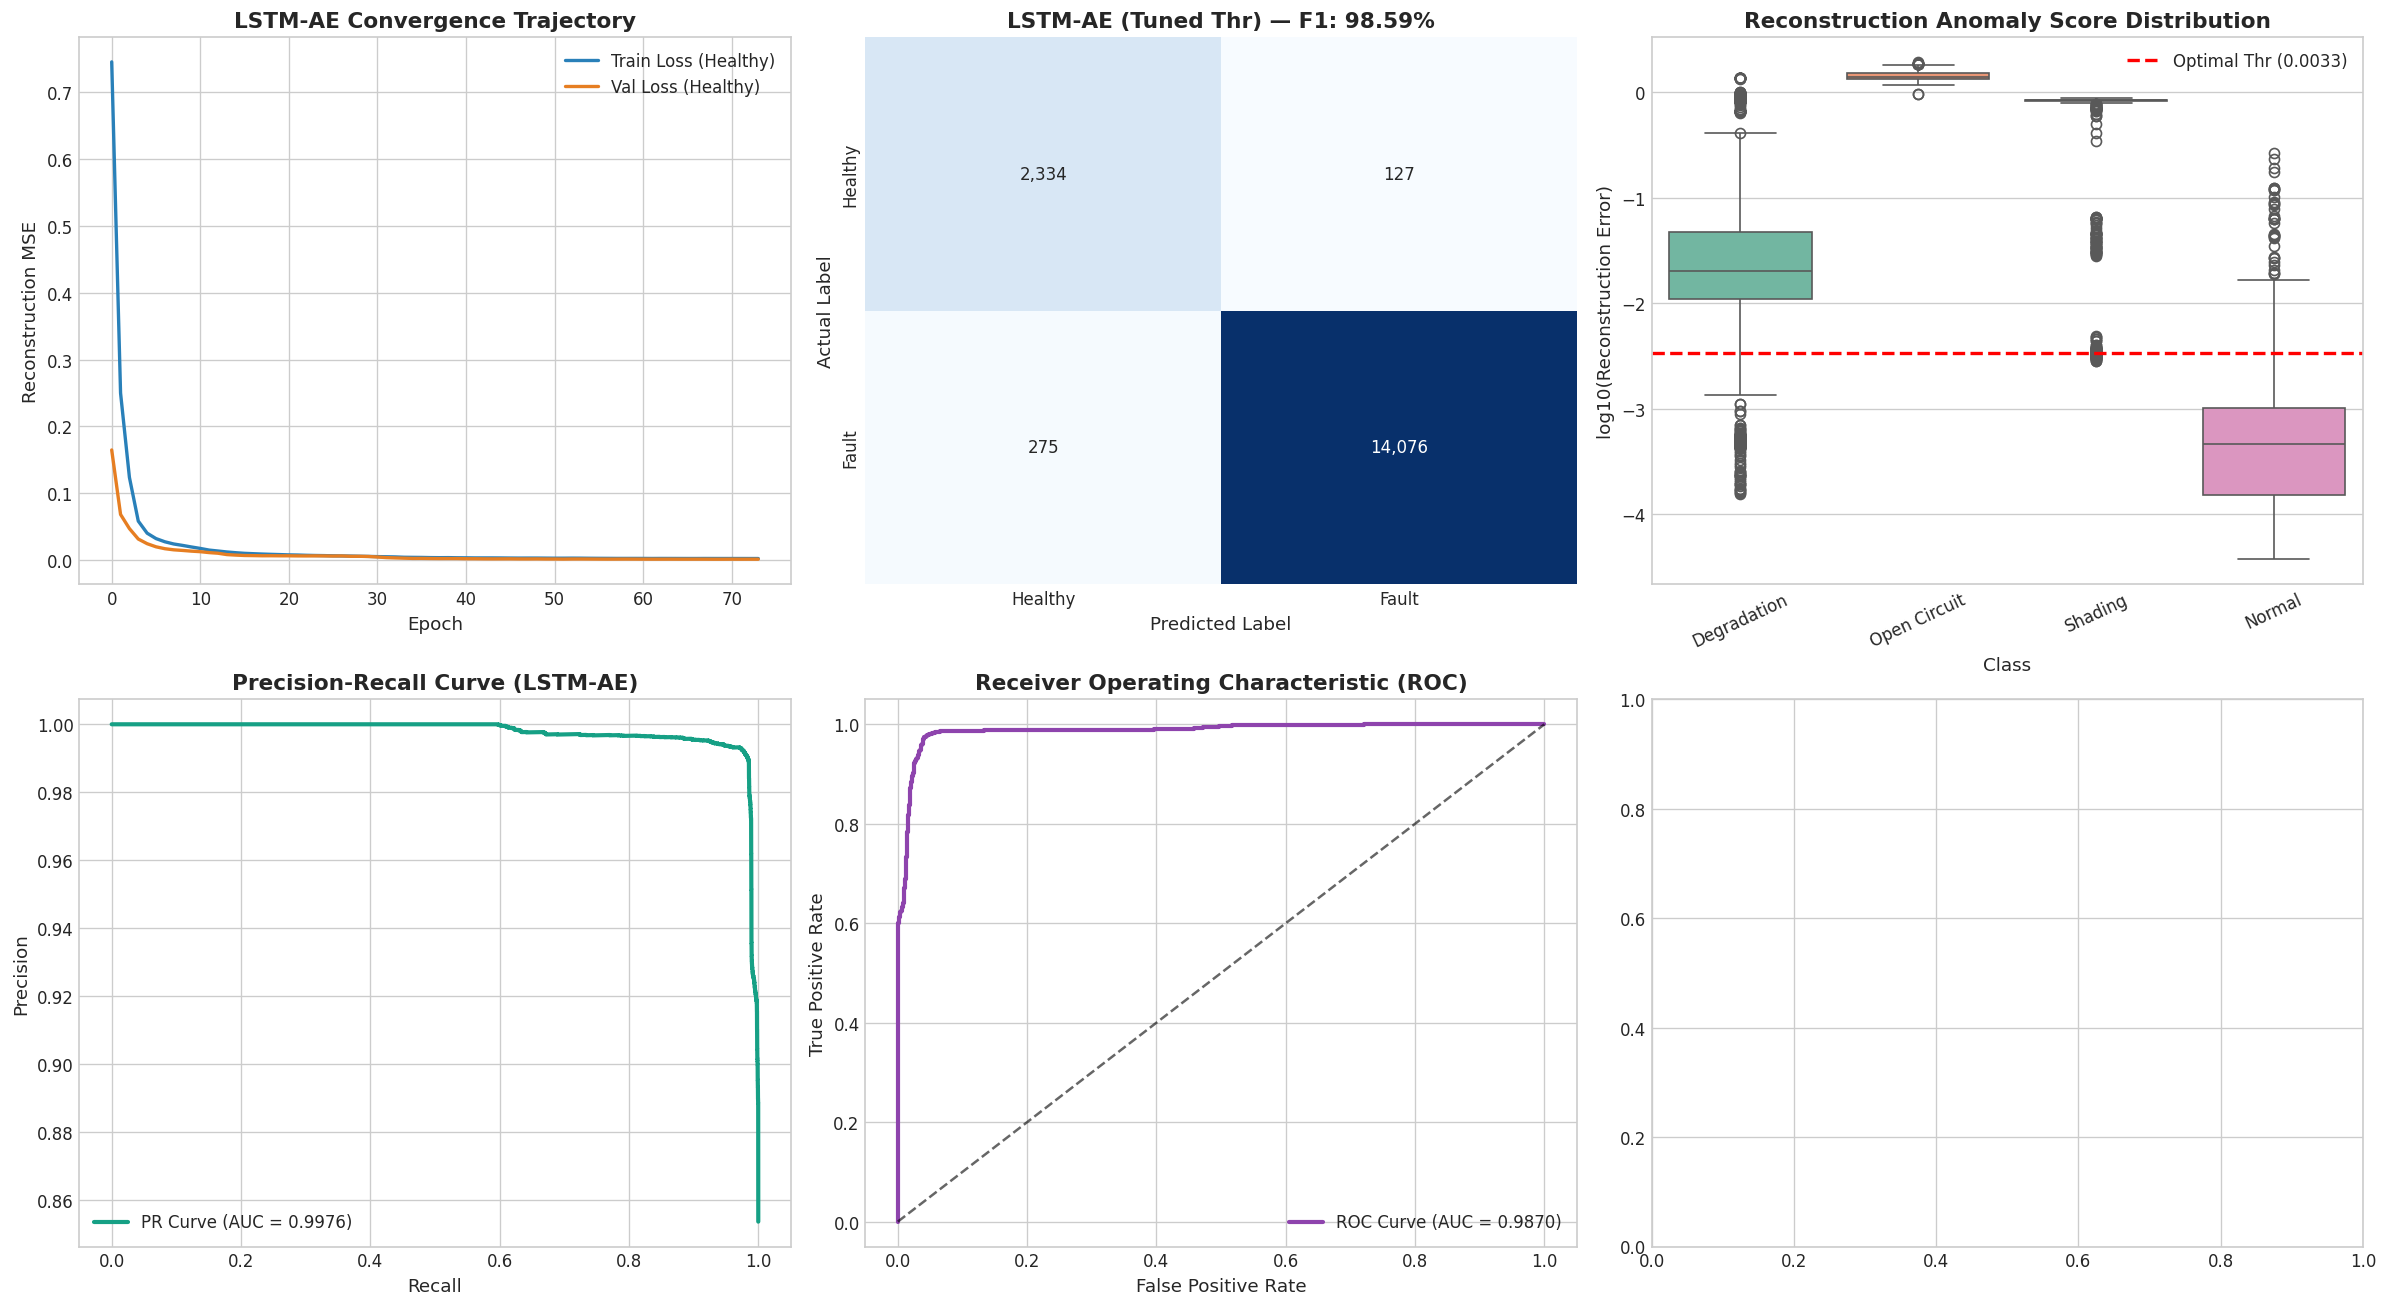

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1. Training & Validation Loss
axes[0, 0].plot(history["train_loss"], label="Train Loss (Healthy)", lw=2, color="#2980b9")
axes[0, 0].plot(history["val_loss"], label="Val Loss (Healthy)", lw=2, color="#e67e22")
axes[0, 0].set_title("LSTM-AE Convergence Trajectory", fontweight="bold")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Reconstruction MSE")
axes[0, 0].legend()

# 2. Confusion Matrix (LSTM-AE Tuned)
cm_ae = confusion_matrix(yb_test, pred_tuned)
sns.heatmap(cm_ae, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0, 1],
            xticklabels=["Healthy", "Fault"], yticklabels=["Healthy", "Fault"])
axes[0, 1].set_title(f"LSTM-AE (Tuned Thr) — F1: {m_tuned['F1']*100:.2f}%", fontweight="bold")
axes[0, 1].set_xlabel("Predicted Label")
axes[0, 1].set_ylabel("Actual Label")

# 3. Anomaly Score Distribution by Class
box_data = pd.DataFrame({
    "Class": yc_test,
    "log10_score": np.log10(test_scores + 1e-9)
})
sns.boxplot(data=box_data, x="Class", y="log10_score", ax=axes[0, 2], palette="Set2")
axes[0, 2].axhline(np.log10(thr_optimal_f1 + 1e-9), color="red", ls="--", lw=2, label=f"Optimal Thr ({thr_optimal_f1:.4f})")
axes[0, 2].set_title("Reconstruction Anomaly Score Distribution", fontweight="bold")
axes[0, 2].set_ylabel("log10(Reconstruction Error)")
axes[0, 2].tick_params(axis="x", rotation=25)
axes[0, 2].legend()

# 4. Precision-Recall Curve
prec, rec, _ = precision_recall_curve(yb_test, test_scores)
axes[1, 0].plot(rec, prec, lw=2.5, color="#16a085", label=f"PR Curve (AUC = {m_tuned['PR_AUC']:.4f})")
axes[1, 0].set_title("Precision-Recall Curve (LSTM-AE)", fontweight="bold")
axes[1, 0].set_xlabel("Recall")
axes[1, 0].set_ylabel("Precision")
axes[1, 0].legend()

# 5. ROC Curve
fpr, tpr, _ = roc_curve(yb_test, test_scores)
axes[1, 1].plot(fpr, tpr, lw=2.5, color="#8e44ad", label=f"ROC Curve (AUC = {m_tuned['ROC_AUC']:.4f})")
axes[1, 1].plot([0, 1], [0, 1], 'k--', alpha=0.6)
axes[1, 1].set_title("Receiver Operating Characteristic (ROC)", fontweight="bold")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("images/lstm_autoencoder_evaluation.png", dpi=300, bbox_inches="tight")
plt.show()

### 12. Model & Pipeline Serialization
Save the trained PyTorch model weights, preprocessors, and metadata bundle.

In [23]:
import os
import joblib
import torch

os.makedirs("models", exist_ok=True)
os.makedirs("images", exist_ok=True)

torch.save(model.state_dict(), "models/lstm_autoencoder_pv_model.pt")

package = {
    
    "model_state_dict": model.state_dict(),
    "model_config": {
        "seq_len": WINDOW_SIZE,
        "n_features": len(FEATURES),
        "hidden_dim": HIDDEN_DIM,
        "latent_dim": LATENT_DIM,
        "dropout": DROPOUT_RATE
    },
    

    "scaler": scaler,
    "features": FEATURES,
    "base_features": BASE_FEATURES,
    "window_size": WINDOW_SIZE,
    "temp_coeff": TEMP_COEFF,
    "irr_min": IRR_MIN,
    "v_min_healthy": V_MIN_HEALTHY,
    
    "threshold_optimal_f1": float(thr_optimal_f1),
    "threshold_p98": float(thr_p98),        
    
    "metrics_tuned": m_tuned,
    "metrics_p98": m_p98
}

joblib.dump(package, "models/lstm_autoencoder_pv_package.pkl")

print("✅ Standalone LSTM-AE model weights and deployment package successfully saved to 'models/'.")


✅ Standalone LSTM-AE model weights and deployment package successfully saved to 'models/'.
